# 06 — Plan around uncertain fatigue with a belief grid

**Goal:** compare QMDP with a planner that accounts for future observations.
A **belief grid** is a list of possible probability mixtures over fatigue levels.
Resolution 0.1 gives 1,001 mixtures. We use five response-time bins, plus correct/incorrect gold-check outcomes. The planner averages over 16 representative observed image contexts. Nearest-grid and nearest-context choices make this an approximation.
Code: [pomdp_grid.py](../src/control/pomdp_grid.py).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Build the belief grid and planner
Planning works backwards from the last decision. For each action it asks how much information and time we expect, what we might observe, and which belief follows.
A gold check has a time cost and no label information, but can improve the belief.

In [2]:
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
from src.sim.fatigue import Scenario
from src.control.pomdp_grid import GridPlanner, belief_grid
from src.eval.stage1 import PlanningModel, population_model, benchmark, summarize, run_policy
contexts = load_contexts()
scenario = Scenario(beta=2)
model = PlanningModel(contexts, scenario, population_model(load_calibration()))
planner = GridPlanner(model)
folder = save_run('notebook06', {'scenario': scenario.dictionary(), 'belief_resolution': .1, 'contexts': 16})
print('Belief grid points:', len(planner.beliefs))
assert len(planner.beliefs) == 1001 and np.allclose(planner.beliefs.sum(1), 1)

Belief grid points: 1001


## 2. Compare planning methods over fatigue strengths
The grid planner is not guaranteed to beat QMDP. We keep negative results.

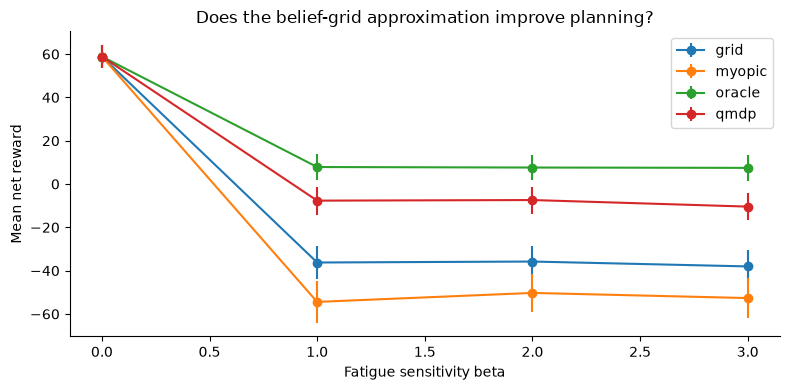

policy,grid,myopic,oracle,qmdp
beta,,,,
0.0,58.87,58.87,58.87,58.87
1.0,-36.24,-54.43,7.85,-7.68
2.0,-35.79,-50.29,7.61,-7.40
3.0,-38.05,-52.66,7.46,-10.43


In [3]:
tables = []
for beta in [0., 1., 2., 3.]:
    condition = Scenario(model='None' if beta == 0 else 'Markov', beta=beta)
    table, path = benchmark(contexts, condition, ['myopic', 'qmdp', 'grid', 'oracle'], episodes=500)
    table['beta'] = beta
    tables.append(table)
comparisons = pd.concat(tables, ignore_index=True)
comparisons.to_csv(folder / 'planner_comparisons.csv.gz', index=False)
for policy, group in comparisons.groupby('policy'):
    means = group.groupby('beta').reward.agg(['mean', 'sem'])
    plt.errorbar(means.index, means['mean'], yerr=means['sem'] * 1.96, marker='o', label=policy)
plt.xlabel('Fatigue sensitivity beta')
plt.ylabel('Mean net reward')
plt.title('Does the belief-grid approximation improve planning?')
plt.legend()
show_plot('01_planner_scores')
display(comparisons.groupby(['beta', 'policy']).reward.mean().unstack().round(2))

## 3. See whether gold checks are actually used
A zero gold rate is a valid result. Response time may already provide enough clues, or the grid approximation may undervalue gold.

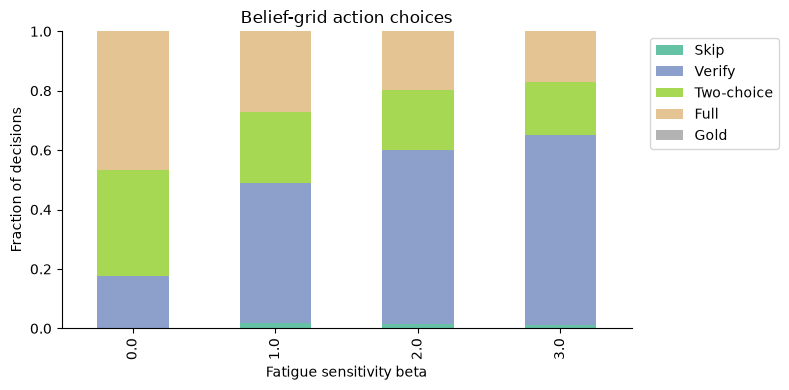

In [4]:
grid_rows = comparisons[comparisons.policy == 'grid']
action_columns = ['count_skip', 'count_verify', 'count_two_choice', 'count_full', 'count_gold']
proportions = grid_rows.groupby('beta')[action_columns].mean() / scenario.steps
proportions.columns = ['Skip', 'Verify', 'Two-choice', 'Full', 'Gold']
proportions.plot.bar(stacked=True, colormap='Set2')
plt.xlabel('Fatigue sensitivity beta')
plt.ylabel('Fraction of decisions')
plt.title('Belief-grid action choices')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_plot('02_gold_check_usage')

## 4. Check sensitivity to the image-context approximation
Keep the same 1,001-point belief grid and compare 16 with 32 representative contexts.
This is one convergence diagnostic, not proof that the approximation is exact.

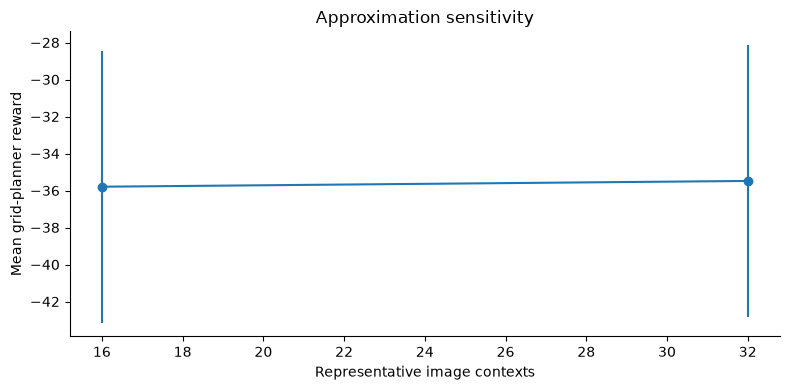

,contexts,reward,reward_se
0,16,-35.794,3.748
1,32,-35.483,3.744


In [5]:
context_results = []
for count in [16, 32]:
    table, path = benchmark(contexts, scenario, ['grid', 'qmdp'], episodes=500, context_count=count)
    row = summarize(table).loc['grid']
    context_results.append({'contexts': count, 'reward': row.reward, 'reward_se': row.reward_se})
context_results = pd.DataFrame(context_results)
context_results.to_csv(folder / 'context_resolution_check.csv', index=False)
plt.errorbar(context_results.contexts, context_results.reward, yerr=context_results.reward_se * 1.96, fmt='o-')
plt.xlabel('Representative image contexts')
plt.ylabel('Mean grid-planner reward')
plt.title('Approximation sensitivity')
show_plot('03_context_resolution')
display(context_results.round(3))

**Interpretation:** the better planner must be decided by results. Extra complexity can lose performance through approximation. In FALCON worlds, warm-up and person-specific curves remain imperfectly represented. In lapse worlds, the five-state belief omits the extra engagement flag. Robustness tests deliberately introduce further model mismatch.